<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta5_g%C3%B6rev5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: NVIDIA RTX PRO 6000 Blackwell Server Edition


Veri seti yolu: /root/.cache/kagglehub/datasets/orvile/hums-x-ray-dataset/versions/1
Dosyalar taranıyor...
İşlenebilecek toplam uygun görüntü sayısı: 589
İşlenen dosya: image_0_1062.jpg


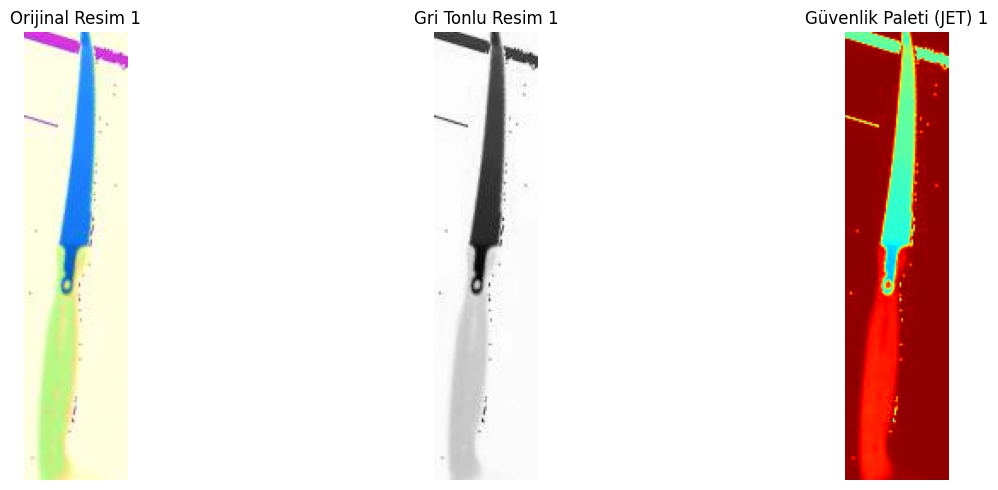

İşlenen dosya: pngImg_78.jpg


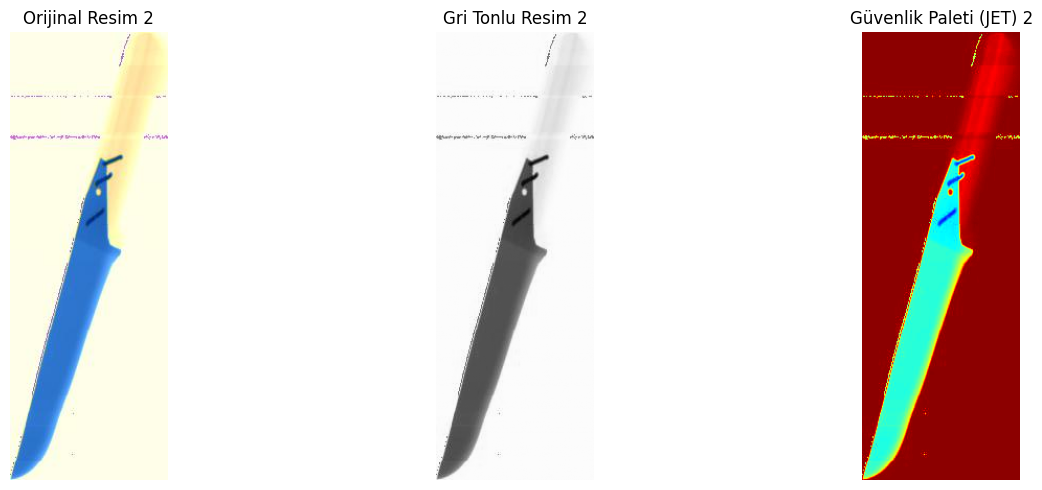

İşlenen dosya: pngImg_82.jpg


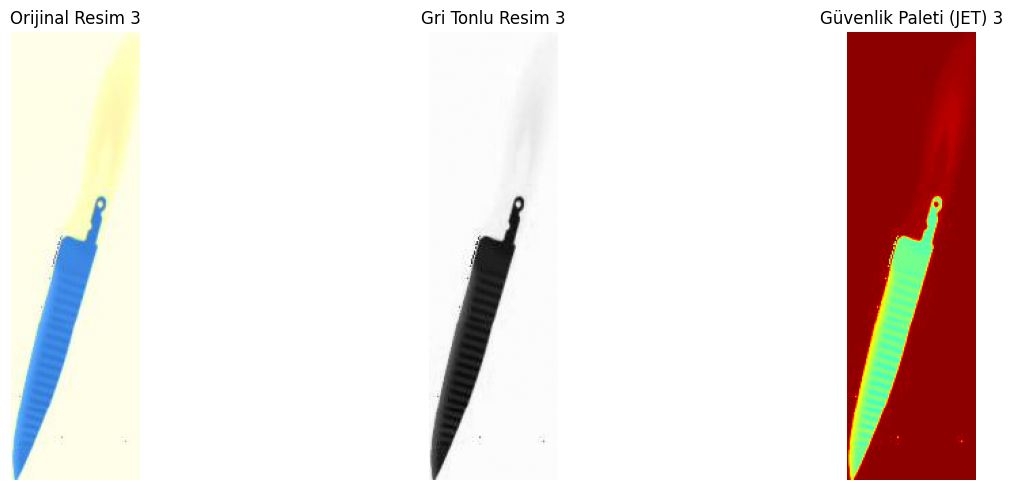

İşlenen dosya: pngImg_74.jpg


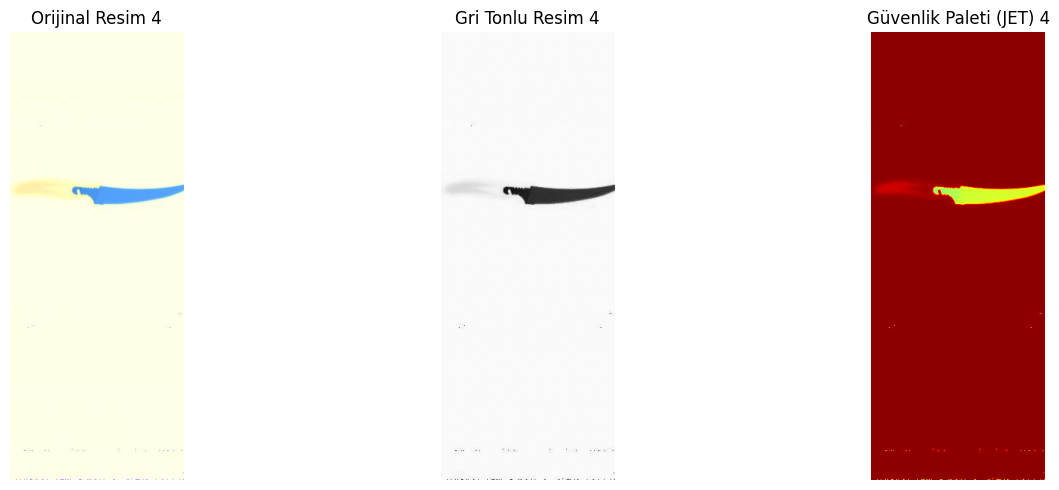

İşlenen dosya: pngImg_79.jpg


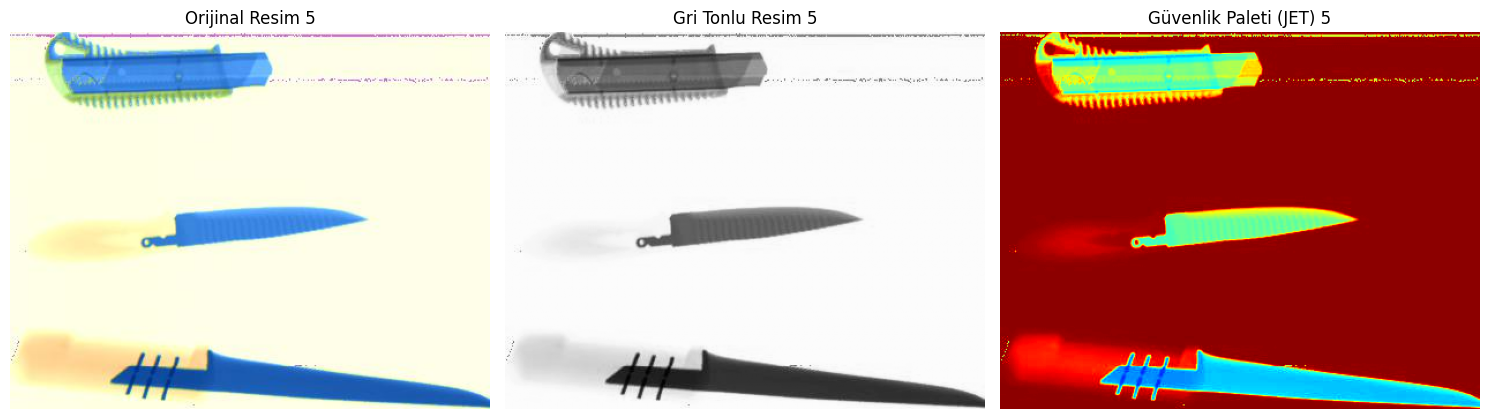

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
import glob

# 1. Veri setini indir (Zaten indiyse cache'den hızlıca yükler)
try:
    import kagglehub
    path = kagglehub.dataset_download("orvile/hums-x-ray-dataset")
    print("Veri seti yolu:", path)
except Exception as e:
    print("İndirme hatası:", e)
    path = "./"

# 2. İndirilen klasördeki ve olası zip/arşiv dosyalarındaki tüm dosyaları tarayalım
print("Dosyalar taranıyor...")
all_files = []
for root, dirs, files in os.walk(path):
    for file in files:
        # Eğer zip dosyası varsa açalım
        if file.endswith('.zip'):
            zip_path = os.path.join(root, file)
            extract_to = os.path.join(root, "extracted_contents")
            os.makedirs(extract_to, exist_ok=True)
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall(extract_to)
                print(f"Arşiv açıldı: {file}")

        # Resim dosyalarını yakalayalım
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif')):
            # Yolunda 'threads' veya 'rgb' geçenleri önceliklendirelim ya da genel toplayalım
            full_path = os.path.join(root, file)
            all_files.append(full_path)

# Ekstra olarak açılan klasörleri de tarayalım
for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif')):
            full_path = os.path.join(root, file)
            if full_path not in all_files:
                all_files.append(full_path)

# 'ThreadsRGB' klasörüne ait olanları filtreleyelim, yoksa tüm resimlerden ilk 5'ini alalım
threads_rgb_images = [f for f in all_files if 'threads' in f.lower() and 'rgb' in f.lower()]
if len(threads_rgb_images) == 0:
    threads_rgb_images = all_files # Bulamazsa genel listeden devam etsin

print(f"İşlenebilecek toplam uygun görüntü sayısı: {len(threads_rgb_images)}")

# İlk 5 görüntüyü seçelim
sample_images = threads_rgb_images[:5]

# 3. Görüntüleri İşleme ve Gösterme
for idx, img_path in enumerate(sample_images):
    print(f"İşlenen dosya: {os.path.basename(img_path)}")
    orig_img = cv2.imread(img_path)
    if orig_img is None:
        continue

    # Gri tonlu resme dönüştürme
    gray_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2GRAY)

    # Güvenlik renk paletiyle renklendirme (JET colormap)
    colored_security_img = cv2.applyColorMap(gray_img, cv2.COLORMAP_JET)

    # Görselleştirme
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB))
    plt.title(f'Orijinal Resim {idx+1}')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(gray_img, cmap='gray')
    plt.title(f'Gri Tonlu Resim {idx+1}')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(colored_security_img, cv2.COLOR_BGR2RGB))
    plt.title(f'Güvenlik Paleti (JET) {idx+1}')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

Renk Paleti Seçiminin Gerekçesi
X-ray bagaj tarama sistemlerinde ve güvenlik kontrol noktalarında operatörlerin tehlikeli nesneleri (silah, bıçak, kesici aletler vb.) hızlı ve hatasız fark etmesi hayati önem taşır. Bu süreçte seçilen renk paleti (cv2.COLORMAP_JET veya benzeri ısı haritası tabanlı paletler) şu gerekçelerle tercih edilmiştir:

İnsan Gözünün Hassasiyeti: İnsan gözü, saf gri tonlamalı görüntülerde yalnızca 30-40 civarında farklı tonu ayırt edebilirken, renk spektrumunda (özellikle mavi-yeşil-sarı-kırmızı geçişlerinde) binlerce farklı tonu çok daha hızlı ve kolay fark edebilir.

Yoğunluk Ayrımı (Density Discrimination): X-ray görüntülemesinde nesnelerin yoğunluğu (atom numarası ve kalınlığı) X-ışınının geçiş oranını belirler. Jet paleti gibi ısı haritası renk paletleri; düşük yoğunluklu bölgeleri mavi/mor, orta yoğunluklu bölgeleri yeşil/sarı, yüksek yoğunluklu (metal vb.) bölgeleri ise kırmızı/turuncu tonlarında göstererek operatörün tehlikeli materyalleri anında ayırt etmesini sağlar.

Orijinal Renkli Resim ile Üretilen Resim Arasındaki Farkların Yorumu
Orijinal Renkli Görüntüler (ThreadsRGB): Veri setindeki orijinal renkli görüntüler, genellikle çift enerjili (dual-energy) X-ray tarayıcılarının fiziksel malzeme ayrımına (organik, inorganik ve metal materyallerin atom numaralarına göre turuncu, mavi ve yeşil renklerle kodlanmasına) dayanır. Yani oradaki renkler gerçek bir nesne boyası değil, malzemenin kimyasal/fiziksel kompozisyonunu gösteren standart güvenlik renk kodlamasıdır.

Ürettiğimiz Görüntüler: Biz ise önce görüntüyü griye çevirip ardından tek kanallı piksel parlaklık değerlerine göre sahte renklendirme (pseudo-coloring) uyguladık. Bu işlem, orijinal verideki çift enerjili fiziksel malzeme ayrımını (organik/inorganik ayrımını) tam olarak yansıtmaz; bunun yerine sadece piksel yoğunluklarının (parlaklık basamaklarının) renklendirilmiş bir haritasını sunar.

Bu nedenle, ürettiğimiz görüntüler görsel olarak güvenlik tarayıcılarına benzetilmiş olsa da, orijinal renkli görüntülerdeki malzeme analizine dayalı hassas renk kodlamasından farklı olarak yalnızca yoğunluk tabanlı bir görselleştirme sunmaktadır.